# 01. Grabetteデータの理解と座標変換の確認

**このノートブックで確かめたこと**

1. Grabetteの`action`に何が記録されているか
2. 変化量を積算すると、映像と矛盾しない「手の動き」が復元できるか
3. 復元した軌跡の座標軸（カメラ座標系）を、ロボットの座標軸にどう対応させればよいか

In [1]:
# パス設定
from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"        # 外部から取得したデータの置き場所
OUT_DIR = ROOT / "outputs"      # このノートブックで作成する図・動画の置き場所

# Grabetteデータセット
GRABETTE_DIR = DATA_DIR / "grabette_pick3_cartesian_480"

# SO-101のMuJoCoモデル
MENAGERIE_DIR = DATA_DIR / "mujoco_menagerie"
MJCF_PATH = MENAGERIE_DIR / "robotstudio_so101" / "so101.xml"
# 描画用のシーン
SCENE_PATH = MENAGERIE_DIR / "robotstudio_so101" / "scene.xml"

OUT_DIR.mkdir(parents=True, exist_ok=True)
# print("ROOT         :", ROOT)
# print("GRABETTE_DIR :", GRABETTE_DIR)
# print("MJCF_PATH    :", MJCF_PATH)

In [2]:
# グラフスタイル設定

# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

In [3]:
# Grabetteデータの読み込み

# LeRobot v3.0形式で、全エピソードの数値データがdata/chunk-000/file-000.parquetにまとまっている。
# ここではpandasで直接読み込み、エピソード番号で切り出す。
import numpy as np
import pandas as pd

grabette_frames = pd.read_parquet(
    GRABETTE_DIR / "data" / "chunk-000" / "file-000.parquet"
) # データ長

grabette_episodes = pd.read_parquet(
    GRABETTE_DIR / "meta" / "episodes" / "chunk-000" / "file-000.parquet"
) # エピソード単位のメタ情報
EPISODE_IDS = sorted(grabette_frames["episode_index"].unique())
GRABETTE_FPS = 50   # meta/info.jsonの"fps"。数値データ・動画ともに50fps

print(f"総フレーム数: {len(grabette_frames):,}")
print(f"エピソード数: {len(EPISODE_IDS)}")

総フレーム数: 91,123
エピソード数: 554


## 1. データの中身を確認する

### 1.1 actionの11列

| 列 | 名前 | 意味 |
|---|---|---|
| 0–2 | dx, dy, dz | 1フレーム前のカメラから見た位置の変化量[m] |
| 3–8 | dr6d_0〜5 | 1フレーム前からの姿勢の変化量（6D回転表現: 回転行列の1・2列目） |
| 9 | proximal | グリッパー根元側の関節角[rad]。大きいほど閉じている |
| 10 | distal | グリッパー先端側の関節角[rad]。SO-101に対応する関節がないため使わない |

このほか`is_lost`列がある。SLAM（映像からの自己位置推定）が位置を見失ったフレームでは1になる。

In [4]:
def get_episode(episode_id):
    """
    1エピソード分のactionとis_lostを取り出す。

    戻り値
    ------
    actions : (T, 11)のfloat64配列
        列0-2 : カメラ座標系での位置の変化量dx, dy, dz [m]
        列3-8 : 姿勢の変化量（6D回転表現）
        列9   : グリッパーのproximal関節角[rad]（大きいほど閉じている）
        列10  : グリッパーのdistal関節角[rad]（本研究では使用しない）
    is_lost : (T,)のbool配列
        TrueのフレームはSLAM（自己位置推定）が位置を見失っている
    """
    rows = grabette_frames[grabette_frames["episode_index"] == episode_id]
    actions = np.array(rows["action"].tolist(), dtype=float)
    is_lost = rows["is_lost"].to_numpy().astype(bool)
    return actions, is_lost

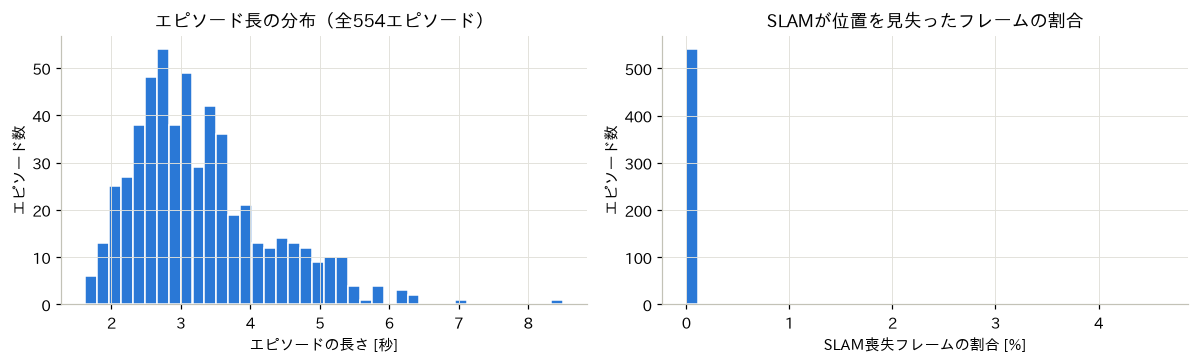

エピソード長: 中央値3.1秒
SLAM lostが1フレームも無いエピソード: 541 / 554


In [5]:
# エピソードの長さと、SLAMが位置を見失ったフレームの割合を調べる
episode_lengths = grabette_frames.groupby("episode_index").size() # データ長group
lost_ratio = grabette_frames.groupby("episode_index")["is_lost"].mean() # lost平均

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(episode_lengths / GRABETTE_FPS, bins=40, color=SERIES_COLORS[0],
             edgecolor="white")
axes[0].set_xlabel("エピソードの長さ [秒]")
axes[0].set_ylabel("エピソード数")
axes[0].set_title(f"エピソード長の分布（全{len(EPISODE_IDS)}エピソード）")

axes[1].hist(lost_ratio * 100, bins=40, color=SERIES_COLORS[0],
             edgecolor="white")
axes[1].set_xlabel("SLAM喪失フレームの割合 [%]")
axes[1].set_ylabel("エピソード数")
axes[1].set_title("SLAMが位置を見失ったフレームの割合")
plt.tight_layout()
plt.savefig(OUT_DIR / "01_episode_overview.png", bbox_inches="tight")
plt.show()

print(f"エピソード長: 中央値{episode_lengths.median() / GRABETTE_FPS:.1f}秒")
print(f"SLAM lostが1フレームも無いエピソード: "
      f"{(lost_ratio == 0).sum()} / {len(lost_ratio)}") # ほぼlostはない

- エピソードの多くは2〜4秒程度。
- SLAMの喪失はほとんどのエピソードで起きていない。喪失したフレームは位置が信用できないため、後の変換ではそのフレームを解かずに飛ばす。

### 1.2 1つのエピソードを映像と並べて見る

In [6]:
# Grabetteデータの読み込み

# 複数エピソードが1本のmp4につながっている。
# エピソード情報のfrom_timestamp（そのエピソードの開始時刻）に「フレーム番号/50fps」を足した時刻のフレームをlerobotの動画読み込み関数で取り出す。
from lerobot.datasets.video_utils import decode_video_frames_pyav

VIDEO_KEY = "observation.images.cam0" # カメラのキー
episodes_meta = grabette_episodes.set_index("episode_index") # メタデータをエピソード番号でキーに

def grabette_video_frames(episode_id, frame_indices):
    """エピソード内のフレーム番号の並びに対応する映像フレーム(N, H, W, 3)を返す。"""
    row = episodes_meta.loc[episode_id]
    chunk = int(row[f"videos/{VIDEO_KEY}/chunk_index"])
    file = int(row[f"videos/{VIDEO_KEY}/file_index"])
    start = float(row[f"videos/{VIDEO_KEY}/from_timestamp"])
    path = (GRABETTE_DIR / "videos" / VIDEO_KEY / f"chunk-{chunk:03d}"
            / f"file-{file:03d}.mp4")
    times = [float(start + i / GRABETTE_FPS) for i in frame_indices]
    frames = decode_video_frames_pyav(path, times,
                                      tolerance_s=1.5 / GRABETTE_FPS,
                                      return_uint8=True)
    return frames.permute(0, 2, 3, 1).numpy()   # (N, C, H, W) → (N, H, W, C)

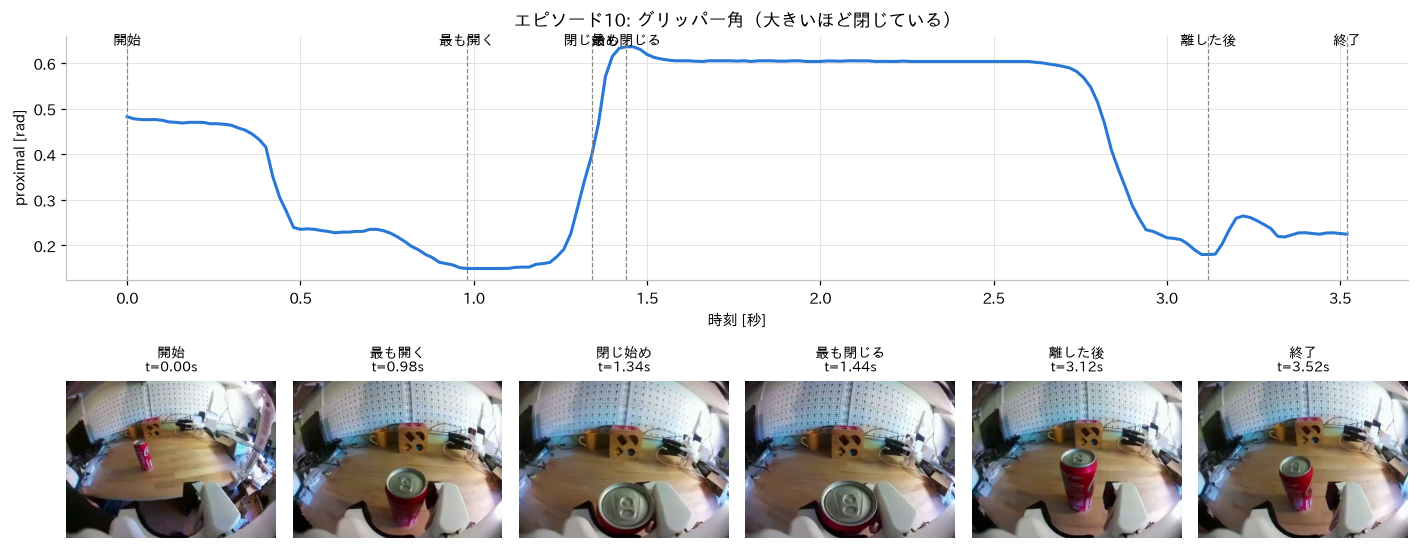

In [7]:
# エピソード10。グリッパー角の変化可視化
EXAMPLE_EP = 10
actions, is_lost = get_episode(EXAMPLE_EP)
n_frames = len(actions)
time_s = np.arange(n_frames) / GRABETTE_FPS
proximal = actions[:, 9]

def grasp_timing(prox):
    """
    proximal角の時系列から、把持に関わる3つの時刻（フレーム番号）を求める。

    t_max   : 最も閉じた時刻
    t_open  : 最も閉じた時刻より前で、最も開いた時刻（掴みにいく直前に手を開いた時刻）
    t_close : t_open以降で、初めて「半分以上閉じた」時刻（閉じ始め）
    「半分以上閉じた」は、エピソード内の最小値〜最大値を0〜1に直した値が
    0.5以上であることとする。
    """
    span = max(prox.max() - prox.min(), 1e-6)
    closed_ratio = (prox - prox.min()) / span
    t_max = int(np.argmax(prox))
    t_open = int(np.argmin(prox[:t_max + 1]))
    t_close = t_open + int(np.argmax(closed_ratio[t_open:] >= 0.5))
    return t_open, t_close, t_max

# 映像を見る時刻: 開始・最も開いた時刻・閉じ始め・最も閉じた時刻・離した後・終了
t_open, t_close, t_max = grasp_timing(proximal)
t_release = t_max + int(np.argmin(proximal[t_max:]))     # 最も閉じた後で最も開いた時刻
key_frames = [0, t_open, t_close, t_max, t_release, n_frames - 1]
key_labels = ["開始", "最も開く", "閉じ始め", "最も閉じる", "離した後", "終了"]

images = grabette_video_frames(EXAMPLE_EP, key_frames)

fig = plt.figure(figsize=(13, 5.6))
grid = fig.add_gridspec(2, 6, height_ratios=[1.0, 1.1])
ax_line = fig.add_subplot(grid[0, :])
ax_line.plot(time_s, proximal, color=SERIES_COLORS[0], label="proximal角")
for frame_id, label in zip(key_frames, key_labels):
    ax_line.axvline(frame_id / GRABETTE_FPS, color=COLOR_MUTED, lw=0.8,
                    ls="--")
    ax_line.text(frame_id / GRABETTE_FPS, proximal.max(), label,
                 ha="center", va="bottom", fontsize=9)
ax_line.set_xlabel("時刻 [秒]")
ax_line.set_ylabel("proximal [rad]")
ax_line.set_title(f"エピソード{EXAMPLE_EP}: グリッパー角（大きいほど閉じている）")
for k, (image, label) in enumerate(zip(images, key_labels)):
    ax = fig.add_subplot(grid[1, k])
    ax.imshow(image)
    ax.set_title(f"{label}\nt={key_frames[k] / GRABETTE_FPS:.2f}s", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "01_example_episode_frames.png", bbox_inches="tight")
plt.show()

- 映像において、物体をつかむ動作とproximal角が連動していることがわかる。
- このことから、proximalを「グリッパーの閉じ具合」として使えると判断。

## 2. 変化量の積算で手の軌跡を復元する

`dx, dy, dz`は「1フレーム前のカメラの向き」を基準にした変化量である。
そのため、単純に足し合わせるだけでは正しい軌跡にならない。
各時刻のカメラの向き$R_t$で変化量を回してから足す必要がある。

先頭フレームは位置を原点、向きを単位行列とする。
したがって復元された軌跡は **撮影開始時のカメラ座標系**（X=右, Y=下, Z=前）で表される。

In [8]:
# ============================================================
# 変化量（デルタ）を積算して絶対軌跡を復元する関数
# ============================================================
# Grabetteのactionは「1フレーム前からどれだけ動いたか」を、
# 1フレーム前のカメラ自身の向きを基準に記録したものである。
# そのため、次の2式を先頭フレームから順に繰り返すと、絶対的な位置と姿勢が得られる。
#
#     位置: p[t+1] = p[t] + R[t] @ dp[t]   （dpを現在の向きR[t]で回してから足す）
#     姿勢: R[t+1] = R[t] @ dR[t]
#
# 先頭フレームは「位置 = 原点」「姿勢 = 単位行列」とする。
# つまり、復元される軌跡は「撮影開始時のカメラ座標系」で表された軌跡になる。


def r6d_to_matrix(r6d):
    """
    6D回転表現（回転行列の1列目と2列目を並べたもの）を3x3回転行列に戻す。

    Gram-Schmidtの直交化で1列目と2列目を直交する単位ベクトルに整え、
    3列目はその外積として求める。
    """
    r6d = np.asarray(r6d, dtype=float)
    shape = r6d.shape[:-1]
    r6d = r6d.reshape(-1, 6)

    a1 = r6d[:, :3]
    a2 = r6d[:, 3:6]

    # 1列目: a1を長さ1に正規化する（長さが0に近い場合は割り算しない）
    norm_a1 = np.linalg.norm(a1, axis=-1, keepdims=True)
    b1 = a1 / np.where(norm_a1 > 1e-8, norm_a1, 1.0)

    # 2列目: a2からb1方向の成分を取り除き、長さ1に正規化する
    b2 = a2 - (b1 * a2).sum(axis=-1, keepdims=True) * b1
    norm_b2 = np.linalg.norm(b2, axis=-1, keepdims=True)
    b2 = b2 / np.where(norm_b2 > 1e-8, norm_b2, 1.0)

    # 3列目: 右手系になるように外積で求める
    b3 = np.cross(b1, b2)

    rotation = np.stack([b1, b2, b3], axis=-1)
    return rotation.reshape(*shape, 3, 3) if shape else rotation[0]


def accumulate_deltas(actions):
    """
    actionの位置・姿勢の変化量を積算し、絶対軌跡を返す。

    戻り値の長さはT+1である。
    添字0は「動き出す前の初期状態」、添字t+1は「t番目の変化量を
    適用した後の状態」を表す。各フレームの位置として使うときは[1:]を取る。
    """
    actions = np.asarray(actions, dtype=float)
    n_frames = len(actions)

    positions = np.zeros((n_frames + 1, 3))
    rotations = np.zeros((n_frames + 1, 3, 3))
    positions[0] = np.zeros(3)      # 初期位置は原点
    rotations[0] = np.eye(3)        # 初期姿勢は単位行列

    for t in range(n_frames):
        delta_position = actions[t, :3]
        delta_rotation = r6d_to_matrix(actions[t, 3:9])

        positions[t + 1] = positions[t] + rotations[t] @ delta_position
        rotations[t + 1] = rotations[t] @ delta_rotation

        # 掛け算を繰り返すと浮動小数点誤差で回転行列が少しずつ歪むため、
        # 特異値分解で最も近い回転行列に毎回戻しておく
        u, _, vt = np.linalg.svd(rotations[t + 1])
        rotations[t + 1] = u @ vt

    return positions, rotations

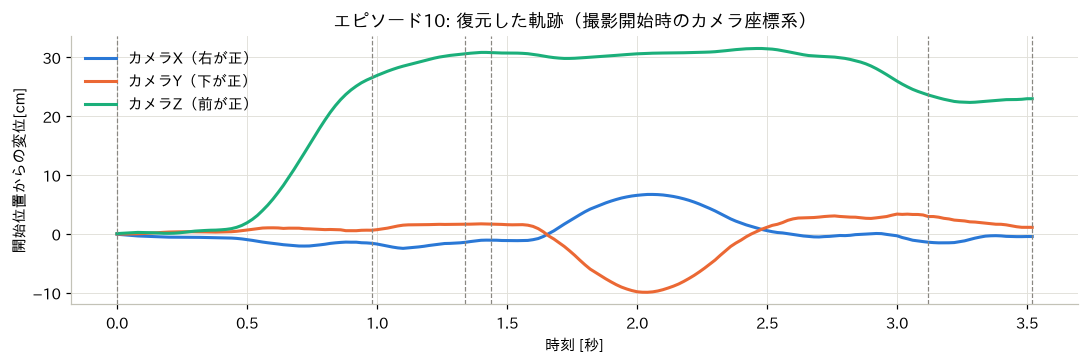

In [9]:
# エピソード10の軌跡を復元し、カメラ座標系の3軸それぞれの変化を描く
positions_cam = accumulate_deltas(actions)[0][1:]   # 添字0（初期状態）を除いて長さT

fig, ax = plt.subplots(figsize=(10, 3.4))
axis_names = ["カメラX（右が正）", "カメラY（下が正）", "カメラZ（前が正）"]
for i in range(3):
    ax.plot(time_s, positions_cam[:, i] * 100, color=SERIES_COLORS[i],
            label=axis_names[i])
for frame_id, label in zip(key_frames, key_labels):
    ax.axvline(frame_id / GRABETTE_FPS, color=COLOR_MUTED, lw=0.8, ls="--")
ax.set_xlabel("時刻 [秒]")
ax.set_ylabel("開始位置からの変位[cm]")
ax.set_title(f"エピソード{EXAMPLE_EP}: 復元した軌跡（撮影開始時のカメラ座標系）")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(OUT_DIR / "01_example_trajectory_camera.png", bbox_inches="tight")
plt.show()

- 前出の映像と見比べて、閉じ始めまでの区間でカメラZが大きく前へ。
- 閉じ始めの後は、カメラYが減少（持ち上げている動作）
- 以上より、復元は成功したと判断。以降は次の変換行列でカメラ座標系をロボット座標系に変換する

In [10]:
# ============================================================
# カメラ座標系 → ロボット座標系 の変換行列
# ============================================================
# Grabetteのカメラ（OAK-D）は一般的なカメラ座標系の規約に従う。
#     カメラX = 右,  カメラY = 下,  カメラZ = 前（奥行き）
# 一方、SO-101（MuJoCoモデル）の座標系は次のとおりである。
#     ロボットX = 前,  ロボットY = 左,  ロボットZ = 上
# この対応を行列で表すと次のようになる（各行が「ロボットの軸 = カメラの軸の組合せ」）。
#     ロボットX =  カメラZ
#     ロボットY = -カメラX
#     ロボットZ = -カメラY
R_CAM_TO_ROBOT = np.array(
    [[0, 0, 1],
     [-1, 0, 0],
     [0, -1, 0]], dtype=float
)

### 3.4 複数エピソードの軌跡

1エピソードだけでなく、多数のエピソードで同じ形になるかを確かめる。
先頭30エピソードの変換後の軌跡（真横から見た図）を重ねて描く。

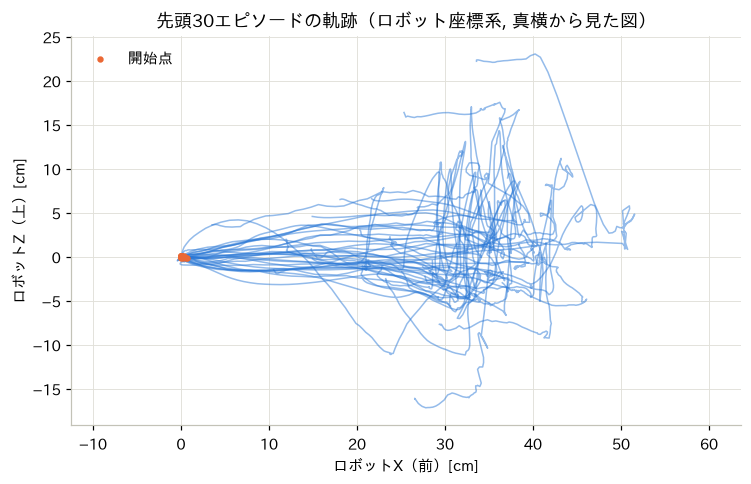

軌跡の広がり（各軸の最大 − 最小）の中央値[cm]: [23.4  7.8 12.6] （X, Y, Zの順）


In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for episode_id in EPISODE_IDS[:30]:
    ep_actions, _ = get_episode(episode_id)
    ep_robot = (R_CAM_TO_ROBOT @ accumulate_deltas(ep_actions)[0][1:].T).T
    ax.plot(ep_robot[:, 0] * 100, ep_robot[:, 2] * 100,
            color=SERIES_COLORS[0], lw=1.0, alpha=0.5)
    ax.scatter(ep_robot[0, 0] * 100, ep_robot[0, 2] * 100,
               color=SERIES_COLORS[1], s=10, zorder=3)
ax.scatter([], [], color=SERIES_COLORS[1], s=10, label="開始点")
ax.set_xlabel("ロボットX（前）[cm]")
ax.set_ylabel("ロボットZ（上）[cm]")
ax.set_title("先頭30エピソードの軌跡（ロボット座標系, 真横から見た図）")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(OUT_DIR / "01_many_trajectories_robot.png", bbox_inches="tight")
plt.show()

extent = []
for episode_id in EPISODE_IDS:
    ep_actions, _ = get_episode(episode_id)
    ep_robot = (R_CAM_TO_ROBOT @ accumulate_deltas(ep_actions)[0][1:].T).T
    extent.append(np.ptp(ep_robot, axis=0))
extent = np.array(extent)
print("軌跡の広がり（各軸の最大 − 最小）の中央値[cm]:",
      np.round(np.median(extent, axis=0) * 100, 1), "（X, Y, Zの順）")

どのエピソードも「前へ進み、上がって戻る」という同じ形をしている。
ただし軌跡の広がりは前後方向（X）に数十cmあり、so-101のスケールと合わない。

軌跡を縮小してSO-101の手が届く範囲に置く必要があるため、以降対応する。